In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(10)

In [16]:
class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)

In [17]:
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

In [18]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [19]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [20]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_mse, hist_wagi, epoki, test=False):
    if (test):
        # Wykres MSE
        plt.figure(figsize=(10, 4))
        plt.plot(range(epoki), hist_mse, color='red')
        plt.title('MSE')
        plt.xlabel('Epoka')
        plt.ylabel('Nieznormalizowane MSE')
        plt.yscale('log')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

        # Wagi
        liczba_warstw = len(hist_wagi)
        if liczba_warstw > 0:
            fig, axes = plt.subplots(1, liczba_warstw, figsize=(5 * liczba_warstw, 5))
            
            if liczba_warstw == 1:
                axes = [axes]

            for numer_warstwy, (idx, historia) in enumerate(hist_wagi.items()):
                ax = axes[numer_warstwy]
                historia_np = np.array(historia)
                epoki_w_historii = historia_np.shape[0]
                wejscia = historia_np.shape[1]
                wyjscia = historia_np.shape[2]
                
                for wej in range(wejscia):
                    for wyj in range(wyjscia):
                        ax.plot(range(epoki_w_historii), historia_np[:, wej, wyj])
                
                ax.set_title(f'Warstwa Liniowa {numer_warstwy + 1}')
                ax.set_xlabel('Epoka')
                ax.set_ylabel('Wartość wagi')
                    
            plt.tight_layout()
            plt.show()

    # Wykresy dopasowania
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Zbiór Treningowy
    ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
    ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
    ax1.set_title('Dopasowanie - Zbiór Treningowy')
    ax1.legend()

    # Zbiór Testowy
    ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
    ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
    ax2.set_title('Dopasowanie - Zbiór Testowy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [21]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, test=False, test_MSE=False):
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)
    y_min = y_train.min(axis=0)
    y_max = y_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    y_train_scaled = (y_train - y_min) / (y_max - y_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    y_test_scaled = (y_test - y_min) / (y_max - y_min)
    
    N = y_train.shape[0] 

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_mse = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Propagacja w przód, w tył i aktualizacja wag
            y_pred_batch = model.forward(X_batch)
            grad_output = y_pred_batch - y_batch
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Obliczanie MSE TRENINGOWEGO co epokę dla wykresu błędu
        y_pred_all = model.forward(X_train_scaled)
        y_pred_unscaled = y_pred_all * (y_max - y_min) + y_min
        mse_treningowe = np.mean((y_train - y_pred_unscaled) ** 2)
        hist_mse.append(mse_treningowe)

        # Obliczanie i wyświetlanie MSE TESTOWEGO co 1000 epok
        if test and i % 1000 == 0:
            if test_MSE:
                # Puszczamy zbiór testowy przez model
                y_pred_test_scaled = model.forward(X_test_scaled)
                y_pred_test_unscaled = y_pred_test_scaled * (y_max - y_min) + y_min
                mse_testowe_krok = np.mean((y_test - y_pred_test_unscaled) ** 2)
                print(f"Krok {i:>5} | MSE Trening: {mse_treningowe:>8.4f} | MSE Test: {mse_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | MSE Trening: {mse_treningowe:>8.4f}")

    print("-" * 50)
    print(f"MSE treningowe FINALNE: {hist_mse[-1]}")

    y_pred_test_scaled = model.forward(X_test_scaled)
    y_pred_test = y_pred_test_scaled * (y_max - y_min) + y_min
    mse_test = np.mean((y_test - y_pred_test) ** 2)
    print(f"MSE testowe FINALNE: {mse_test}")

    # Rysowanie wykresów
    # wykresy(X_train, y_train, X_test, y_test, y_pred_unscaled, y_pred_test, hist_mse, hist_wagi, epoki, test)

    return hist_mse[-1], mse_test

In [22]:
def train_N(X_train, y_train, X_test, y_test, konfiguracje, N=5):
    wyniki = []
    
    for nazwa_opt, konfig in konfiguracje.items():
        print(f"Rozpoczynam testy dla: {nazwa_opt}")
        
        for proba in range(N):
            warstwy = konfig['buduj_architekture']()
            
            model = MLP(warstwy, 
                        learning_rate=konfig['lr'], 
                        optymalizacja=konfig.get('opt'), 
                        wspolczynnik=0.9)
            
            mse_train, mse_test = train(X_train, y_train, X_test, y_test, model, 
                                        epoki=konfig['epoki'], 
                                        rozmiar_batcha=konfig['batch'], 
                                        test=False, test_MSE=False)
            
            wyniki.append({
                'Optymalizator': nazwa_opt,
                'Próba': proba + 1,
                'MSE_Trening': mse_train,
                'MSE_Test': mse_test
            })
            print(f"   Próba {proba + 1}/{N} zakończona (Test MSE: {mse_test:.2f})")
            
    return pd.DataFrame(wyniki)

In [23]:
N = 4

# Dane square large

In [24]:
square_large_test = pd.read_csv("mio1/regression/square-large-test.csv")
square_large_train = pd.read_csv("mio1/regression/square-large-training.csv")
X_train = square_large_train[['x']].to_numpy()
y_train = square_large_train[['y']].to_numpy()
X_test = square_large_test[['x']].to_numpy()
y_test = square_large_test[['y']].to_numpy()

In [25]:
def arch_square():
    return (warstwa_liniowa(1, 10, 'xavier'), sigmoid(), 
            warstwa_liniowa(10, 5, 'xavier'), sigmoid(), 
            warstwa_liniowa(5, 1, 'xavier'))

konfig_square = {
    'Brak':    {'buduj_architekture': arch_square, 'lr': 0.1,   'opt': None,      'epoki': 30000, 'batch': 64},
    'Moment':  {'buduj_architekture': arch_square, 'lr': 0.1,   'opt': 'moment',  'epoki': 30000, 'batch': 64},
    'RMSProp': {'buduj_architekture': arch_square, 'lr': 0.0001, 'opt': 'RMSProp', 'epoki': 30000, 'batch': 64}
}

print("--- DANE SQUARE-LARGE ---")
df_square = train_N(X_train, y_train, X_test, y_test, konfig_square, N=N)
display(df_square)

--- DANE SQUARE-LARGE ---
Rozpoczynam testy dla: Brak
--------------------------------------------------
MSE treningowe FINALNE: 0.6108780233703619
MSE testowe FINALNE: 4.386200453374115
   Próba 1/4 zakończona (Test MSE: 4.39)
--------------------------------------------------
MSE treningowe FINALNE: 0.2533801383413791
MSE testowe FINALNE: 8.098359273911555
   Próba 2/4 zakończona (Test MSE: 8.10)
--------------------------------------------------
MSE treningowe FINALNE: 0.6234655751649041
MSE testowe FINALNE: 1.5433240554499563
   Próba 3/4 zakończona (Test MSE: 1.54)
--------------------------------------------------
MSE treningowe FINALNE: 1.346069919896212
MSE testowe FINALNE: 13.369023106299977
   Próba 4/4 zakończona (Test MSE: 13.37)
Rozpoczynam testy dla: Moment
--------------------------------------------------
MSE treningowe FINALNE: 0.09961488834138832
MSE testowe FINALNE: 9.782560249377802
   Próba 1/4 zakończona (Test MSE: 9.78)
-------------------------------------------

,Optymalizator,Próba,MSE_Trening,MSE_Test
0,Brak,1,0.610878,4.386200
1,Brak,2,0.253380,8.098359
2,Brak,3,0.623466,1.543324
3,Brak,4,1.346070,13.369023
4,Moment,1,0.099615,9.782560
5,Moment,2,0.111728,6.997215
6,Moment,3,0.163826,17.134712
7,Moment,4,0.158746,9.530718
8,RMSProp,1,0.312133,37.307120
9,RMSProp,2,0.182202,28.106442


In [26]:
statystyki_square = df_square.groupby('Optymalizator')[['MSE_Trening', 'MSE_Test']].agg(['mean', 'std'])
display(statystyki_square)

MSE_Trening             MSE_Test          
                     mean       std       mean       std
Optymalizator                                           
Brak             0.708448  0.458400   6.849227  5.108398
Moment           0.133479  0.032554  10.861301  4.367340
RMSProp          0.273280  0.084732  31.547182  6.037017

# Dane steps large

In [27]:
steps_large_test = pd.read_csv("mio1/regression/steps-large-test.csv")
steps_large_train = pd.read_csv("mio1/regression/steps-large-training.csv")
X_train = steps_large_train[['x']].to_numpy()
y_train = steps_large_train[['y']].to_numpy()
X_test = steps_large_test[['x']].to_numpy()
y_test = steps_large_test[['y']].to_numpy()

In [28]:
def arch_steps():
    return (warstwa_liniowa(1, 10, 'xavier'), sigmoid(), 
            warstwa_liniowa(10, 10, 'xavier'), sigmoid(), 
            warstwa_liniowa(10, 1, 'xavier'))

konfig_steps = {
    'Brak':    {'buduj_architekture': arch_steps, 'lr': 0.8,   'opt': None,      'epoki': 18000, 'batch': 32},
    'Moment':  {'buduj_architekture': arch_steps, 'lr': 0.1,   'opt': 'moment',  'epoki': 18000, 'batch': 32},
    'RMSProp': {'buduj_architekture': arch_steps, 'lr': 0.001, 'opt': 'RMSProp', 'epoki': 18000, 'batch': 32}
}

print("\n--- DANE STEPS-LARGE ---")
df_steps = train_N(X_train, y_train, X_test, y_test, konfig_steps, N=N)
display(df_steps)


--- DANE STEPS-LARGE ---
Rozpoczynam testy dla: Brak
--------------------------------------------------
MSE treningowe FINALNE: 77.94621501703709
MSE testowe FINALNE: 73.45958054783735
   Próba 1/4 zakończona (Test MSE: 73.46)
--------------------------------------------------
MSE treningowe FINALNE: 42.28766555108029
MSE testowe FINALNE: 40.530070733560905
   Próba 2/4 zakończona (Test MSE: 40.53)
--------------------------------------------------
MSE treningowe FINALNE: 40.583084800386345
MSE testowe FINALNE: 39.22263119156096
   Próba 3/4 zakończona (Test MSE: 39.22)
--------------------------------------------------
MSE treningowe FINALNE: 32.82633441948934
MSE testowe FINALNE: 29.556987904310613
   Próba 4/4 zakończona (Test MSE: 29.56)
Rozpoczynam testy dla: Moment
--------------------------------------------------
MSE treningowe FINALNE: 27.116115990990934
MSE testowe FINALNE: 24.093272213633867
   Próba 1/4 zakończona (Test MSE: 24.09)
-----------------------------------------

,Optymalizator,Próba,MSE_Trening,MSE_Test
0,Brak,1,77.946215,73.459581
1,Brak,2,42.287666,40.530071
2,Brak,3,40.583085,39.222631
3,Brak,4,32.826334,29.556988
4,Moment,1,27.116116,24.093272
5,Moment,2,28.611853,25.258879
6,Moment,3,25.945213,24.414810
7,Moment,4,26.691450,24.421507
8,RMSProp,1,20.378971,15.442037
9,RMSProp,2,18.221071,15.740261


In [29]:
statystyki_steps = df_steps.groupby('Optymalizator')[['MSE_Trening', 'MSE_Test']].agg(['mean', 'std'])
display(statystyki_steps)

MSE_Trening              MSE_Test           
                     mean        std       mean        std
Optymalizator                                             
Brak            48.410825  20.116181  45.692318  19.147458
Moment          27.091158   1.123401  24.547117   0.498619
RMSProp         18.864568   1.015773  15.546593   0.193957

# Dane multimodal large

In [30]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")
X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

In [31]:
def arch_multi():
    return (warstwa_liniowa(1, 12, 'xavier'), sigmoid(), 
            warstwa_liniowa(12, 12, 'xavier'), sigmoid(), 
            warstwa_liniowa(12, 1, 'xavier'))

konfig_multi = {
    'Brak':    {'buduj_architekture': arch_multi, 'lr': 0.3,   'opt': None,      'epoki': 15000, 'batch': 64},
    'Moment':  {'buduj_architekture': arch_multi, 'lr': 0.1,  'opt': 'moment',  'epoki': 15000, 'batch': 64},
    'RMSProp': {'buduj_architekture': arch_multi, 'lr': 0.001, 'opt': 'RMSProp', 'epoki': 15000, 'batch': 64}
}

print("\n--- DANE MULTIMODAL-LARGE ---")
df_multi = train_N(X_train, y_train, X_test, y_test, konfig_multi, N=N)
display(df_multi)


--- DANE MULTIMODAL-LARGE ---
Rozpoczynam testy dla: Brak
--------------------------------------------------
MSE treningowe FINALNE: 16.27288959572707
MSE testowe FINALNE: 11.641119337299957
   Próba 1/4 zakończona (Test MSE: 11.64)
--------------------------------------------------
MSE treningowe FINALNE: 35.26512777881016
MSE testowe FINALNE: 33.03421048658412
   Próba 2/4 zakończona (Test MSE: 33.03)
--------------------------------------------------
MSE treningowe FINALNE: 25.73511215139731
MSE testowe FINALNE: 21.24757271531722
   Próba 3/4 zakończona (Test MSE: 21.25)
--------------------------------------------------
MSE treningowe FINALNE: 16.41083868355405
MSE testowe FINALNE: 12.011125775465192
   Próba 4/4 zakończona (Test MSE: 12.01)
Rozpoczynam testy dla: Moment
--------------------------------------------------
MSE treningowe FINALNE: 7.859960567656845
MSE testowe FINALNE: 3.4496854761927813
   Próba 1/4 zakończona (Test MSE: 3.45)
---------------------------------------

,Optymalizator,Próba,MSE_Trening,MSE_Test
0,Brak,1,16.272890,11.641119
1,Brak,2,35.265128,33.034210
2,Brak,3,25.735112,21.247573
3,Brak,4,16.410839,12.011126
4,Moment,1,7.859961,3.449685
5,Moment,2,8.489962,3.952929
6,Moment,3,8.425798,4.225257
7,Moment,4,8.757257,4.598150
8,RMSProp,1,7.962726,3.085708
9,RMSProp,2,7.968784,4.831242


In [32]:
statystyki_multi = df_multi.groupby('Optymalizator')[['MSE_Trening', 'MSE_Test']].agg(['mean', 'std'])
display(statystyki_multi)

MSE_Trening             MSE_Test           
                     mean       std       mean        std
Optymalizator                                            
Brak            23.420992  9.053109  19.483507  10.067655
Moment           8.383244  0.377231   4.056505   0.483327
RMSProp          8.431268  2.327943   4.809731   3.108083

Wykresy dla Square-Large:


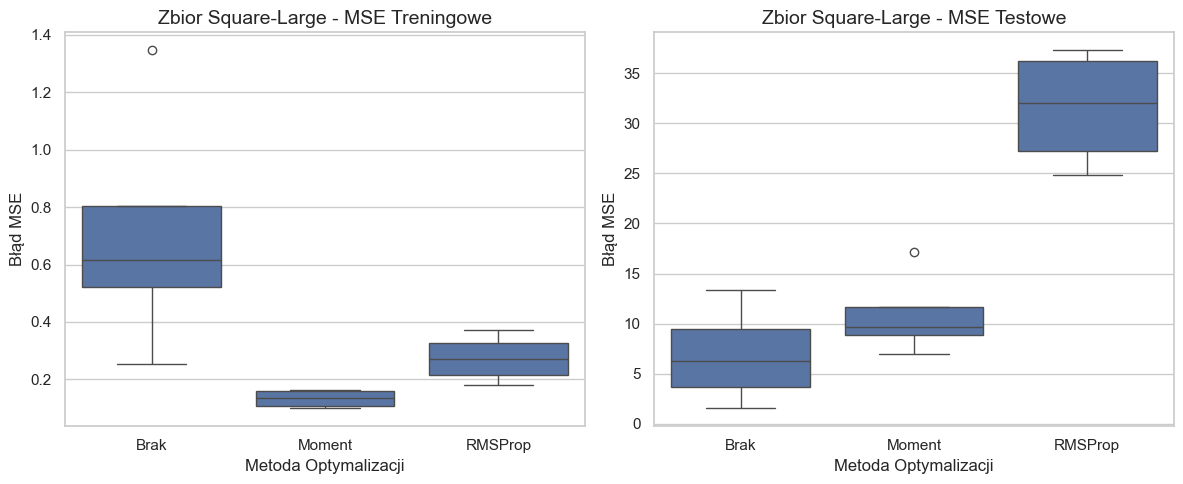

Wykresy dla Steps-Large:


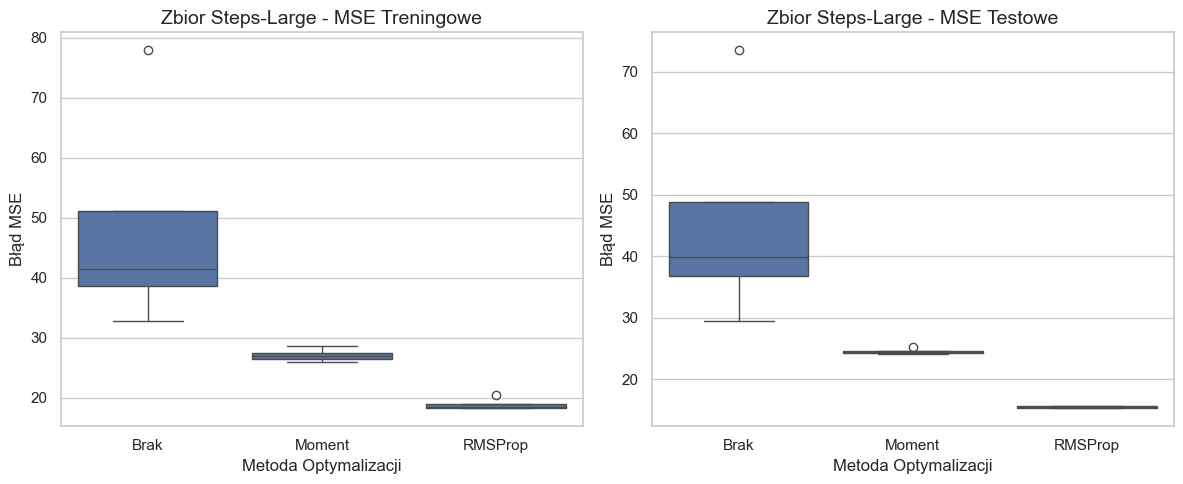

Wykresy dla Multimodal-Large:


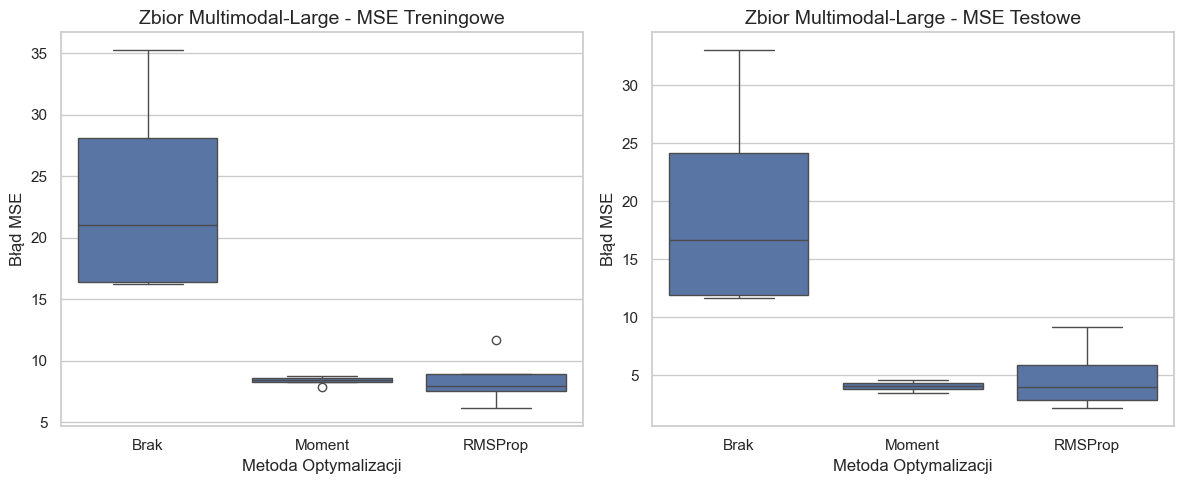

In [33]:
def rysuj_boxploty(df, nazwa_zbioru):
    sns.set_theme(style="whitegrid")
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Boxplot dla MSE Treningowego
    sns.boxplot(data=df, x='Optymalizator', y='MSE_Trening', ax=axes[0])
    axes[0].set_title(f'{nazwa_zbioru} - MSE Treningowe', fontsize=14)
    axes[0].set_ylabel('Błąd MSE')
    axes[0].set_xlabel('Metoda Optymalizacji')
    
    # Boxplot dla MSE Testowego
    sns.boxplot(data=df, x='Optymalizator', y='MSE_Test', ax=axes[1])
    axes[1].set_title(f'{nazwa_zbioru} - MSE Testowe', fontsize=14)
    axes[1].set_ylabel('Błąd MSE')
    axes[1].set_xlabel('Metoda Optymalizacji')
    
    plt.tight_layout()
    plt.show()

# Wywołanie dla wszystkich zbiorów:
print("Wykresy dla Square-Large:")
rysuj_boxploty(df_square, 'Zbior Square-Large')

print("Wykresy dla Steps-Large:")
rysuj_boxploty(df_steps, 'Zbior Steps-Large')

print("Wykresy dla Multimodal-Large:")
rysuj_boxploty(df_multi, 'Zbior Multimodal-Large')